# E-Commerce Sales & Customer Analytics

This notebook follows the workflow **raw data -> cleaning -> analysis -> customer metrics -> recommendations**. Every result is calculated from `data/Online Retail.xlsx`; no business result is typed into the notebook.

The primary sales dataset contains positive-quantity, positive-price, non-cancelled transactions. Returns and cancellations are profiled separately before exclusion.

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
IMAGE_DIR = ROOT / 'images'
IMAGE_DIR.mkdir(exist_ok=True)

preferred_files = [DATA_DIR / 'Online Retail.xlsx', DATA_DIR / 'online retail .xlsx']
excel_files = [path for path in preferred_files if path.exists()]
if not excel_files:
    excel_files = sorted(DATA_DIR.glob('*.xlsx')) + sorted(DATA_DIR.glob('*.xls'))

if not excel_files:
    raise FileNotFoundError(f'No Excel file found in {DATA_DIR}')

INPUT_FILE = excel_files[0]
OUTPUT_FILE = DATA_DIR / 'cleaned_online_retail.csv'

print(f'Using file: {INPUT_FILE.name}')

Using file: online retail .xlsx


## 1. Load and inspect the raw data

In [26]:
df = pd.read_excel(INPUT_FILE, engine='openpyxl')

# Standardize headers immediately
normalize_name = lambda name: ''.join(ch.lower() for ch in str(name) if ch.isalnum())
column_aliases = {
    'invoiceno': 'InvoiceNo',
    'stockcode': 'StockCode',
    'description': 'Description',
    'quantity': 'Quantity',
    'invoicedate': 'InvoiceDate',
    'unitprice': 'UnitPrice',
    'customerid': 'CustomerID',
    'country': 'Country'
}
df = df.rename(columns={
    column: column_aliases.get(normalize_name(column), column)
    for column in df.columns
})

required_columns = set(column_aliases.values())
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

raw_missing = df.isna().sum().sort_values(ascending=False).to_frame('missing_values')
print(f'Shape: {df.shape}')
print('Columns:', df.columns.tolist())
display(df.head())
df.info()
display(df.describe(include='all').T)
display(raw_missing)
print('Exact duplicate rows:', df.duplicated().sum())
print('Unique invoices:', df['InvoiceNo'].nunique())
print('Unique customers:', df['CustomerID'].nunique())
print('Unique products:', df['StockCode'].nunique())
print('Countries:', df['Country'].nunique())
print('Raw date range:', df['InvoiceDate'].min(), 'to', df['InvoiceDate'].max())

Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_values
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Exact duplicate rows: 5268
Unique invoices: 25900
Unique customers: 4372
Unique products: 4070
Countries: 38
Raw date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


## 2. Clean transactions

`CustomerID` is missing for some transactions, so those rows are retained for product, revenue, and geography analysis but excluded from identifiable-customer metrics. `Description` is filled with a label only to keep grouped outputs readable. Exact duplicate rows are removed because they repeat the same transaction record. Invoices beginning with `C` are treated as cancellations.

In [27]:
clean = df.copy()

clean['InvoiceDate'] = pd.to_datetime(clean['InvoiceDate'], errors='coerce')
clean['Quantity'] = pd.to_numeric(clean['Quantity'], errors='coerce')
clean['UnitPrice'] = pd.to_numeric(clean['UnitPrice'], errors='coerce')
clean['CustomerID'] = pd.to_numeric(clean['CustomerID'], errors='coerce').astype('Int64')
clean['InvoiceNo'] = clean['InvoiceNo'].astype('string').str.strip()
clean['StockCode'] = clean['StockCode'].astype('string').str.strip()
clean['Country'] = clean['Country'].astype('string').str.strip()
clean['Description'] = clean['Description'].astype('string').str.strip()

clean['IsCancelled'] = clean['InvoiceNo'].str.upper().str.startswith('C', na=False)
clean['IsReturn'] = clean['Quantity'].lt(0)

before_duplicates = len(clean)
clean = clean.drop_duplicates().copy()

invalid_date = clean['InvoiceDate'].isna()
non_positive_quantity = clean['Quantity'].le(0)
non_positive_price = clean['UnitPrice'].le(0)
invalid_rows = invalid_date | non_positive_quantity | non_positive_price

transaction_quality = pd.Series({
    'Raw rows': len(df),
    'Exact duplicate rows': int(df.duplicated().sum()),
    'Cancelled invoice rows': int(clean['IsCancelled'].sum()),
    'Return rows': int(clean['IsReturn'].sum()),
    'Missing invoice dates': int(invalid_date.sum()),
    'Non-positive quantity rows': int(non_positive_quantity.sum()),
    'Non-positive price rows': int(non_positive_price.sum()),
    'Rows removed as duplicates': before_duplicates - len(clean),
    'Valid completed-sale rows': int((~clean['IsCancelled'] & ~invalid_rows).sum())
})
display(transaction_quality.to_frame('count'))

# Completed sales exclude cancellations, returns, malformed dates, and non-positive prices.
valid = clean[
    ~clean['IsCancelled']
    & ~invalid_rows
].copy()
valid['Description'] = valid['Description'].fillna('Unknown product')
valid['Country'] = valid['Country'].fillna('Unknown country')
valid['Revenue'] = valid['Quantity'] * valid['UnitPrice']
valid['Year'] = valid['InvoiceDate'].dt.year.astype('int64')
valid['Month'] = valid['InvoiceDate'].dt.month.astype('int64')
valid['YearMonth'] = valid['InvoiceDate'].dt.to_period('M').astype(str)
valid['DayOfWeek'] = valid['InvoiceDate'].dt.day_name()
valid['Hour'] = valid['InvoiceDate'].dt.hour.astype('int64')

print(f'Valid sales rows: {len(valid):,}')
display(valid.head())

,count
Raw rows,541909
Exact duplicate rows,5268
Cancelled invoice rows,9251
Return rows,10587
Missing invoice dates,0
Non-positive quantity rows,10587
Non-positive price rows,2512
Rows removed as duplicates,5268
Valid completed-sale rows,524878


Valid sales rows: 524,878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsReturn,Revenue,Year,Month,YearMonth,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,15.30,2010,12,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,20.34,2010,12,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,22.00,2010,12,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,20.34,2010,12,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,20.34,2010,12,2010-12,Wednesday,8


In [28]:
export_columns = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Year', 'Month', 'YearMonth', 'DayOfWeek', 'Hour']
valid[export_columns].to_csv(OUTPUT_FILE, index=False)
print(f'Saved {len(valid):,} rows to {OUTPUT_FILE}')

Saved 524,878 rows to c:\Users\m\OneDrive\Music\Ecommerce-Analytics\data\cleaned_online_retail.csv


## 3. Core business KPIs

In [29]:
identified = valid[valid['CustomerID'].notna()].copy()
total_revenue = valid['Revenue'].sum()
total_orders = valid['InvoiceNo'].nunique()
total_customers = identified['CustomerID'].nunique()
total_units = valid['Quantity'].sum()
average_order_value = total_revenue / total_orders
customer_order_counts = identified.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_customers = int((customer_order_counts > 1).sum())
one_time_customers = int((customer_order_counts == 1).sum())
kpis = pd.Series({
    'Total revenue': total_revenue,
    'Total orders': total_orders,
    'Total identifiable customers': total_customers,
    'Average order value': average_order_value,
    'Total units sold': total_units,
    'Repeat customer rate': repeat_customers / total_customers
})
display(kpis)
print(f'Repeat customers: {repeat_customers:,}; one-time customers: {one_time_customers:,}')

Total revenue                   1.064211e+07
Total orders                    1.996000e+04
Total identifiable customers    4.338000e+03
Average order value             5.331719e+02
Total units sold                5.572420e+06
Repeat customer rate            6.558322e-01
dtype: float64

Repeat customers: 2,845; one-time customers: 1,493


## 4. Time and sales trend analysis

,YearMonth,Revenue,Orders,Customers,AverageOrderValue
0,2010-12,821452.730,1559,885,526.910026
1,2011-01,689811.610,1086,741,635.185645
2,2011-02,522545.560,1100,758,475.041418
3,2011-03,716215.260,1454,974,492.582710
4,2011-04,536968.491,1246,856,430.953845
5,2011-05,769296.610,1681,1056,457.642243
6,2011-06,760547.010,1533,991,496.116771
7,2011-07,718076.121,1475,949,486.831268
8,2011-08,757841.380,1361,935,556.826877
9,2011-09,1056435.192,1837,1266,575.087203


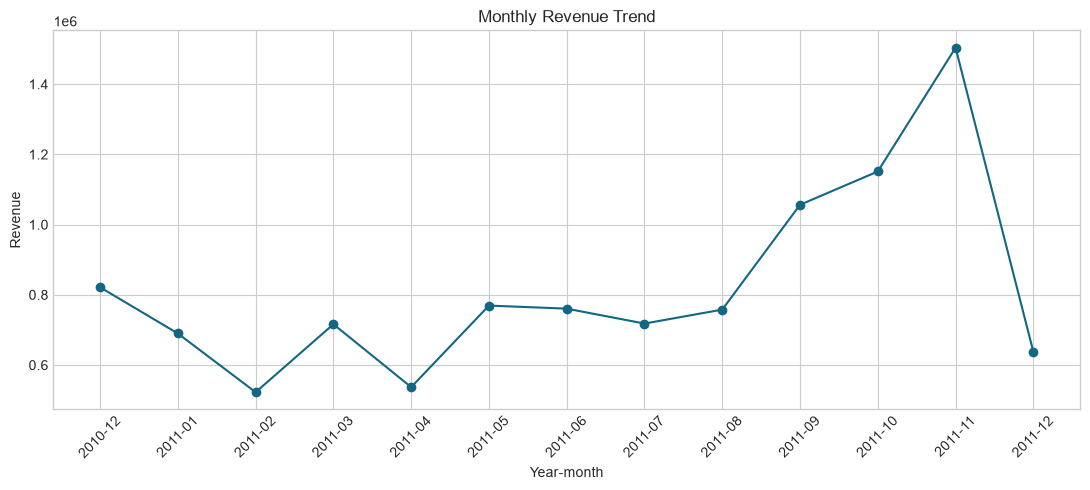

In [30]:
monthly = valid.groupby('YearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Customers=('CustomerID', 'nunique')
).reset_index()
monthly['AverageOrderValue'] = monthly['Revenue'] / monthly['Orders']
display(monthly)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly['YearMonth'], monthly['Revenue'], marker='o', color='#126782')
ax.set(title='Monthly Revenue Trend', xlabel='Year-month', ylabel='Revenue')
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'monthly_revenue.png', dpi=160)
plt.show()

## 5. Product and geographic analysis

Top 10 products by revenue


,,Revenue,Quantity
StockCode,Description,,
DOT,DOTCOM POSTAGE,206248.77,706
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
47566,PARTY BUNTING,99445.23,18283
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
POST,POSTAGE,78101.88,3150
M,Manual,77750.27,6984


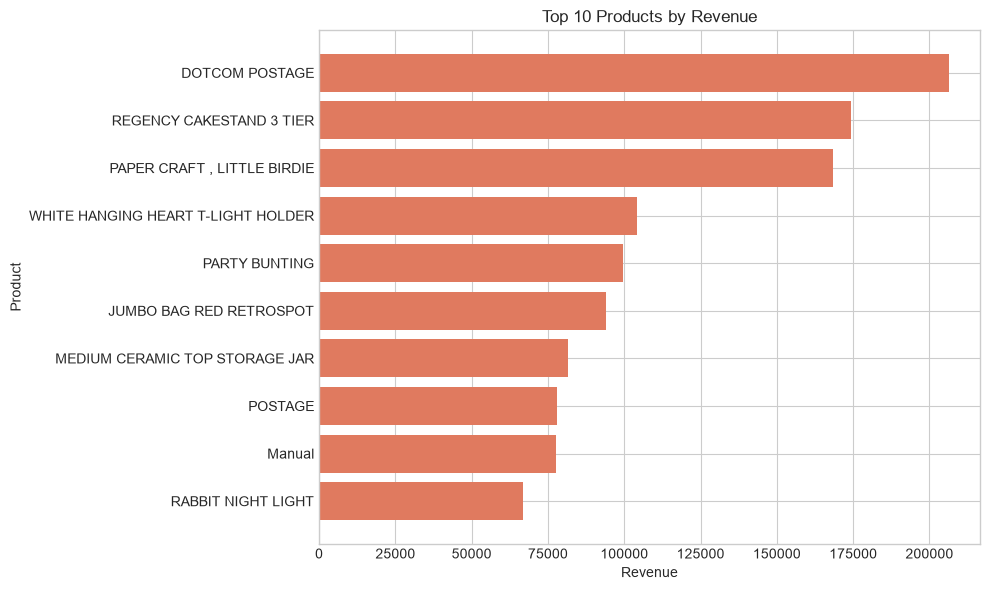

,Revenue,Orders,Customers,AverageOrderValue
Country,,,,
United Kingdom,9001744.094,18019,3920,499.569571
Netherlands,285446.340,94,9,3036.663191
EIRE,283140.520,288,3,983.126806
Germany,228678.400,457,94,500.390372
France,209625.370,392,87,534.758597
Australia,138453.810,57,9,2429.014211
Spain,61558.560,90,30,683.984000
Switzerland,57067.600,54,21,1056.807407
Belgium,41196.340,98,25,420.370816


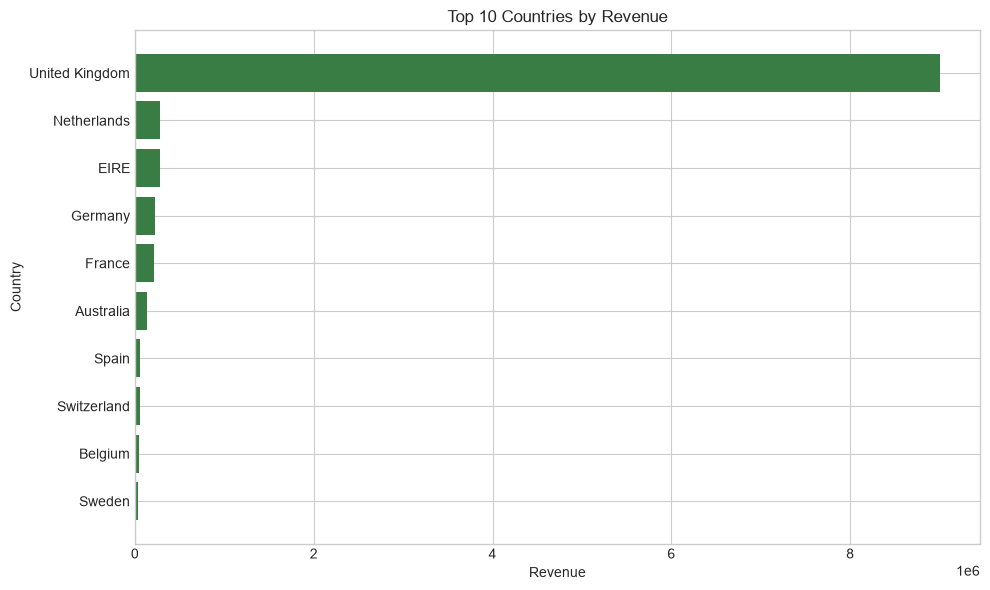

In [31]:
analysis = valid.copy()
analysis['Description'] = analysis.get(
    'Description', 'Unknown product'
).fillna('Unknown product').astype(str)

product_summary = (
    analysis.groupby(['StockCode', 'Description'], dropna=False)
    .agg(Revenue=('Revenue', 'sum'), Quantity=('Quantity', 'sum'))
    .sort_values('Revenue', ascending=False)
)

print('Top 10 products by revenue')
display(product_summary.head(10))

top_products = product_summary.head(10).sort_values('Revenue')
product_labels = top_products.index.get_level_values('Description')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(product_labels, top_products['Revenue'], color='#e07a5f')
ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue')
ax.set_ylabel('Product')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'top_products_revenue.png', dpi=160)
plt.show()

country_summary = (
    analysis.groupby('Country')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('InvoiceNo', 'nunique'),
        Customers=('CustomerID', 'nunique')
    )
    .sort_values('Revenue', ascending=False)
)

country_summary['AverageOrderValue'] = (
    country_summary['Revenue'] / country_summary['Orders']
)

display(country_summary.head(15))

top_countries = country_summary.head(10).sort_values('Revenue')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_countries.index, top_countries['Revenue'], color='#3a7d44')
ax.set_title('Top 10 Countries by Revenue')
ax.set_xlabel('Revenue')
ax.set_ylabel('Country')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'top_countries_revenue.png', dpi=160)
plt.show()

## 6. Customer value and repeat purchasing

,CustomerID,TotalRevenue,Orders,TotalQuantity,FirstPurchase,LastPurchase,AverageOrderValue,CustomerType
1689,14646,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,3838.438630,Repeat
4201,18102,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,4327.621667,Repeat
3728,17450,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,4225.886739,Repeat
3008,16446,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.250000,Repeat
1879,14911,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,714.980945,Repeat
55,12415,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,5948.310952,Repeat
1333,14156,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.092364,Repeat
3771,17511,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,2937.496129,Repeat
2702,16029,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,1283.346667,Repeat
0,12346,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000,One-time


,CustomerType,Customers,Revenue,RevenueShare
0,One-time,1493,613989.561,0.069087
1,Repeat,2845,8273219.333,0.930913


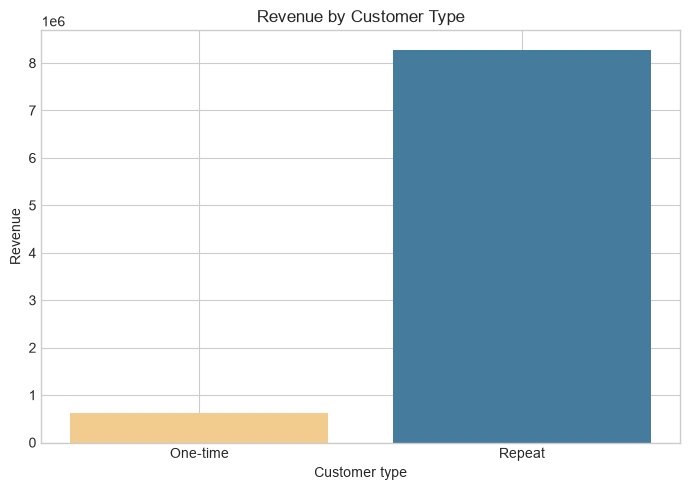

In [32]:
customer_metrics = identified.groupby('CustomerID').agg(
    TotalRevenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max')
).reset_index()
customer_metrics['AverageOrderValue'] = customer_metrics['TotalRevenue'] / customer_metrics['Orders']
customer_metrics['CustomerType'] = np.where(customer_metrics['Orders'] > 1, 'Repeat', 'One-time')
repeat_summary = customer_metrics.groupby('CustomerType').agg(
    Customers=('CustomerID', 'count'), Revenue=('TotalRevenue', 'sum')
).reset_index()
repeat_summary['RevenueShare'] = repeat_summary['Revenue'] / repeat_summary['Revenue'].sum()
display(customer_metrics.sort_values('TotalRevenue', ascending=False).head(10))
display(repeat_summary)
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(repeat_summary['CustomerType'], repeat_summary['Revenue'], color=['#f2cc8f', '#457b9d'])
ax.set(title='Revenue by Customer Type', xlabel='Customer type', ylabel='Revenue')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'repeat_customer_revenue.png', dpi=160)
plt.show()

## 7. RFM segmentation

Recency is measured in days from the latest transaction in the dataset. Frequency is distinct invoice count and Monetary is revenue. Quartile scores are calculated from the observed customer distribution, then combined into transparent rule-based segments.

,Customers,Revenue,AverageFrequency
Segment,,,
High-Value Customers,1312,6476424.831,9.399390
At-Risk Customers,1337,1424614.592,2.841436
Low-Frequency Customers,1487,892653.491,1.199731
Loyal Customers,202,93515.980,3.054455


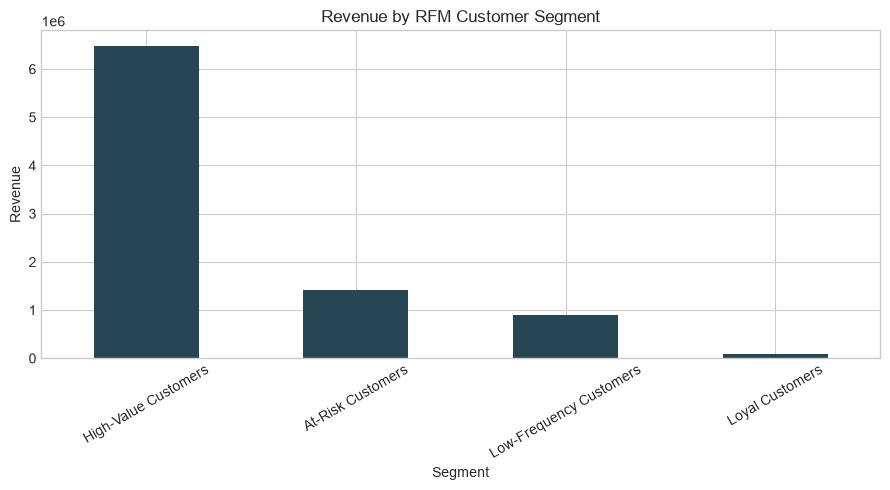

In [33]:
analysis_date = valid['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = identified.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (analysis_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()
rfm['RScore'] = pd.qcut(rfm['Recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['FScore'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['MScore'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
def classify(row):
    if row['RScore'] >= 3 and row['FScore'] >= 3 and row['MScore'] >= 3:
        return 'High-Value Customers'
    if row['RScore'] >= 3 and row['FScore'] >= 3:
        return 'Loyal Customers'
    if row['RScore'] <= 2 and row['FScore'] >= 2:
        return 'At-Risk Customers'
    if row['FScore'] <= 2:
        return 'Low-Frequency Customers'
    return 'Regular Customers'
rfm['Segment'] = rfm.apply(classify, axis=1)
segment_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'), Revenue=('Monetary', 'sum'), AverageFrequency=('Frequency', 'mean')
).sort_values('Revenue', ascending=False)
display(segment_summary)
rfm.to_csv(ROOT / 'data' / 'customer_rfm.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
segment_summary['Revenue'].plot(kind='bar', ax=ax, color='#264653')
ax.set(title='Revenue by RFM Customer Segment', xlabel='Segment', ylabel='Revenue')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'rfm_segment_revenue.png', dpi=160)
plt.show()

## 8. Export tables for SQL and Power BI

Load `cleaned_online_retail.csv` into a table named `analytical_sales`. The `rfm` table can be loaded as `customer_metrics`. The SQL file in `sql/business_queries.sql` uses these names.

In [34]:
# Add customer attributes to the transaction-level dataset for Power BI.
customer_attributes = rfm[['CustomerID', 'Segment']].merge(
    customer_metrics[['CustomerID', 'CustomerType']],
    on='CustomerID',
    how='left'
)
power_bi_sales = valid.merge(customer_attributes, on='CustomerID', how='left')
power_bi_sales['CustomerType'] = power_bi_sales['CustomerType'].fillna('Unknown')
power_bi_sales['Segment'] = power_bi_sales['Segment'].fillna('Unidentified')
power_bi_sales.to_csv(DATA_DIR / 'power_bi_sales.csv', index=False)

print('Power BI fields:', power_bi_sales.columns.tolist())
print('Power BI rows:', f'{len(power_bi_sales):,}')
print('Generated files:')
for path in sorted(DATA_DIR.glob('*.csv')):
    print(path)
print('Charts:')
for path in sorted(IMAGE_DIR.glob('*.png')):
    print(path)

Power BI fields: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancelled', 'IsReturn', 'Revenue', 'Year', 'Month', 'YearMonth', 'DayOfWeek', 'Hour', 'Segment', 'CustomerType']
Power BI rows: 524,878
Generated files:
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\data\cleaned_online_retail.csv
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\data\customer_rfm.csv
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\data\power_bi_sales.csv
Charts:
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\images\monthly_revenue.png
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\images\repeat_customer_revenue.png
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\images\rfm_segment_revenue.png
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\images\top_countries_revenue.png
c:\Users\m\OneDrive\Music\Ecommerce-Analytics\images\top_products_revenue.png


## 9. Automated SQLite database and SQL analysis

This stage is fully reproducible. It recreates the SQLite database, imports the generated CSV files into the required tables, reads the numbered queries from `sql/business_queries.sql`, executes them, and saves each result as a CSV in `sql/results/`. Rerunning the notebook refreshes the database and all result files from the current dataset.

In [35]:
import re
import sqlite3

SQL_FILE = ROOT / 'sql' / 'business_queries.sql'
SQLITE_FILE = DATA_DIR / 'ecommerce_analytics.sqlite'
SQL_RESULTS_DIR = ROOT / 'sql' / 'results'
SQL_RESULTS_DIR.mkdir(exist_ok=True)

sales_for_sql = pd.read_csv(
    DATA_DIR / 'cleaned_online_retail.csv',
    dtype={'InvoiceNo': 'string', 'StockCode': 'string'}
)
rfm_for_sql = pd.read_csv(DATA_DIR / 'customer_rfm.csv')

# Replace both tables so every run reflects the current generated datasets.
with sqlite3.connect(SQLITE_FILE) as connection:
    connection.execute('DROP TABLE IF EXISTS analytical_sales')
    connection.execute('DROP TABLE IF EXISTS customer_metrics')
    sales_for_sql.to_sql('analytical_sales', connection, if_exists='replace', index=False)
    rfm_for_sql.to_sql('customer_metrics', connection, if_exists='replace', index=False)

sql_text = SQL_FILE.read_text(encoding='utf-8')
query_blocks = re.split(r'(?=^--\s*\d+\.)', sql_text, flags=re.MULTILINE)
queries = []
for block in query_blocks:
    match = re.match(r'^--\s*(\d+)\.\s*(.*)$', block, flags=re.MULTILINE)
    if not match:
        continue
    query_number = int(match.group(1))
    query_title = match.group(2).strip()
    query_sql = re.sub(r'^--.*$', '', block, flags=re.MULTILINE).strip()
    if query_sql:
        queries.append((query_number, query_title, query_sql))

query_summary = []
with sqlite3.connect(SQLITE_FILE) as connection:
    for query_number, query_title, query_sql in queries:
        result = pd.read_sql_query(query_sql, connection)
        result_path = SQL_RESULTS_DIR / f'query_{query_number:02d}.csv'
        result.to_csv(result_path, index=False)
        query_summary.append({
            'QueryNumber': query_number,
            'Title': query_title,
            'RowsReturned': len(result),
            'ResultFile': str(result_path.relative_to(ROOT))
        })
        print(f'Query {query_number}: {query_title} ({len(result):,} rows)')
        display(result.head(10))

query_summary = pd.DataFrame(query_summary).sort_values('QueryNumber')
query_summary.to_csv(SQL_RESULTS_DIR / 'query_summary.csv', index=False)
print(f'SQLite database: {SQLITE_FILE}')
print(f'SQL result files: {SQL_RESULTS_DIR}')

Query 1: Total revenue (1 rows)


,total_revenue
0,10642110.8


Query 2: Total orders, customers, and units (1 rows)


,total_orders,total_customers,total_units_sold
0,18532,4338,5152002


Query 3: Monthly revenue and orders (13 rows)


...

Query 10: Customer revenue ranking and share of revenue (4,338 rows)


,CustomerID,revenue,customer_rank,revenue_share_percent
0,14646.0,280206.02,1,3.15
1,18102.0,259657.30,2,2.92
2,17450.0,194390.79,3,2.19
3,16446.0,168472.50,4,1.90
4,14911.0,143711.17,5,1.62
5,12415.0,124914.53,6,1.41
6,14156.0,117210.08,7,1.32
7,17511.0,91062.38,8,1.02
8,16029.0,80850.84,9,0.91
9,12346.0,77183.60,10,0.87


Query 11: RFM-style segment summary. customer_metrics is created by the notebook. (4 rows)


,Segment,customers,revenue,average_orders
0,High-Value Customers,1312,6476424.83,9.40
1,At-Risk Customers,1337,1424614.59,2.84
2,Low-Frequency Customers,1487,892653.49,1.20
3,Loyal Customers,202,93515.98,3.05


SQLite database: c:\Users\m\OneDrive\Music\Ecommerce-Analytics\data\ecommerce_analytics.sqlite
SQL result files: c:\Users\m\OneDrive\Music\Ecommerce-Analytics\sql\results
